# Monte Carlo Simulation of Election Outcomes

**Research question:** How does the number of randomly sampled voting tables affect the reliability of identifying the winner of a close election?

This independently written portfolio case study adapts simulation and statistical-inference techniques practised in LSE PP422, using a historical dataset of voting tables from Peru’s **2021 presidential runoff** between Pedro Castillo and Keiko Fujimori. The provided source filename says “2020”, but the election studied took place in 2021.

**Scope:** This is a simulation of simple random samples of voting tables from a known finite population. It is **not** an election forecast, evidence of electoral irregularities, or a model of real-world polling design.

## 1. Data and validation

The dataset has one row per voting table, with votes for both candidates, invalid votes and total votes cast. Some rows have missing candidate counts or zero total votes. To keep sample margins well-defined and comparable, the simulations use complete cases with positive votes cast. We report exclusions rather than silently imputing votes.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

path = Path("Peru Election 2020.csv")
if not path.exists():
    raise FileNotFoundError("Place 'Peru Election 2020.csv' next to this notebook; see README for data access notes.")
raw = pd.read_csv(path)
required = ["castillo", "fujimori", "votes_cast"]
complete = raw.dropna(subset=required).copy()
valid = complete.loc[complete["votes_cast"] > 0].copy()
assert (valid["castillo"] >= 0).all() and (valid["fujimori"] >= 0).all()
assert np.allclose(valid["castillo"] + valid["fujimori"] + valid["invalid"], valid["votes_cast"])
print(f"Original voting tables: {len(raw):,}")
print(f"Excluded missing required counts: {len(raw) - len(complete):,}")
print(f"Excluded zero-vote tables: {len(complete) - len(valid):,}")
print(f"Voting tables analysed: {len(valid):,}")

Original voting tables: 86,488
Excluded missing required counts: 321
Excluded zero-vote tables: 0
Voting tables analysed: 86,167


## 2. Population vote margin

The margin is **(Castillo votes − Fujimori votes) / total votes cast × 100**, measured in percentage points. The denominator includes invalid votes, matching the approach in the original PP422 exercise. The complete-case population margin can differ slightly from the aggregate using all available rows.

In [2]:
def vote_margin_pp(frame):
    return 100 * (frame["castillo"].sum() - frame["fujimori"].sum()) / frame["votes_cast"].sum()

population_margin = vote_margin_pp(valid)
print(f"Population margin (complete-case): {population_margin:.3f} percentage points")
print("Population winner:", "Castillo" if population_margin > 0 else "Fujimori")

Population margin (complete-case): 0.172 percentage points
Population winner: Castillo


## 3. Monte Carlo sampling experiment

Draw **1,000 independent simple random samples without replacement within each sample**, first with 5 tables and then with 100. Samples may overlap across simulation repetitions. A fixed random seed ensures reproducible results. The resulting margin distribution shows how sample-to-sample uncertainty can change the inferred winner.

In [3]:
rng = np.random.default_rng(422)
values = valid[["castillo", "fujimori", "votes_cast"]].to_numpy()

def simulate_margins(sample_size, repetitions=1_000):
    margins = np.empty(repetitions)
    for i in range(repetitions):
        indices = rng.choice(len(values), size=sample_size, replace=False)
        sampled = values[indices]
        margins[i] = 100 * (sampled[:, 0].sum() - sampled[:, 1].sum()) / sampled[:, 2].sum()
    return margins

margins_5 = simulate_margins(5)
margins_100 = simulate_margins(100)
summary = pd.DataFrame([
    {"Tables sampled": n,
     "Mean margin (pp)": margins.mean(),
     "SD of margin (pp)": margins.std(ddof=1),
     "Correct winner (%)": 100 * np.mean((margins > 0) == (population_margin > 0))}
    for n, margins in [(5, margins_5), (100, margins_100)]
])
display(summary.round(2))

,Tables sampled,Mean margin (pp),SD of margin (pp),Correct winner (%)
0,5,-0.16,18.24,48.0
1,100,-0.08,4.19,50.3


## 4. Visualise sampling uncertainty

The dashed line marks the complete-case population margin; the dotted line marks a tie. A sample can identify the wrong winner even if its margin estimate is not unusually extreme.

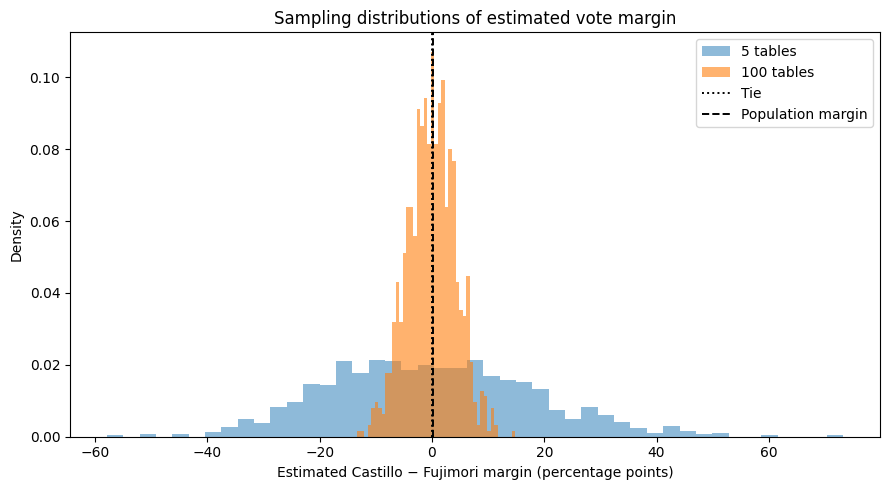

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(margins_5, bins=45, alpha=0.5, label="5 tables", density=True)
ax.hist(margins_100, bins=45, alpha=0.6, label="100 tables", density=True)
ax.axvline(0, color="black", linestyle=":", linewidth=1.4, label="Tie")
ax.axvline(population_margin, color="black", linestyle="--", linewidth=1.4, label="Population margin")
ax.set(xlabel="Estimated Castillo − Fujimori margin (percentage points)",
       ylabel="Density", title="Sampling distributions of estimated vote margin")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Optional confidence-interval coverage experiment

Using the empirical standard deviation of the **100-table** simulated margins as an approximate standard error, construct a normal-approximation 90% interval around each simulated estimate. The share of intervals containing the known population margin illustrates repeated-sampling coverage under this simplified setup. **Caution:** Using one shared simulation-derived standard error is an instructional approximation, not a practical poll-level variance estimator.

Approximate 90% interval coverage: 90.9%


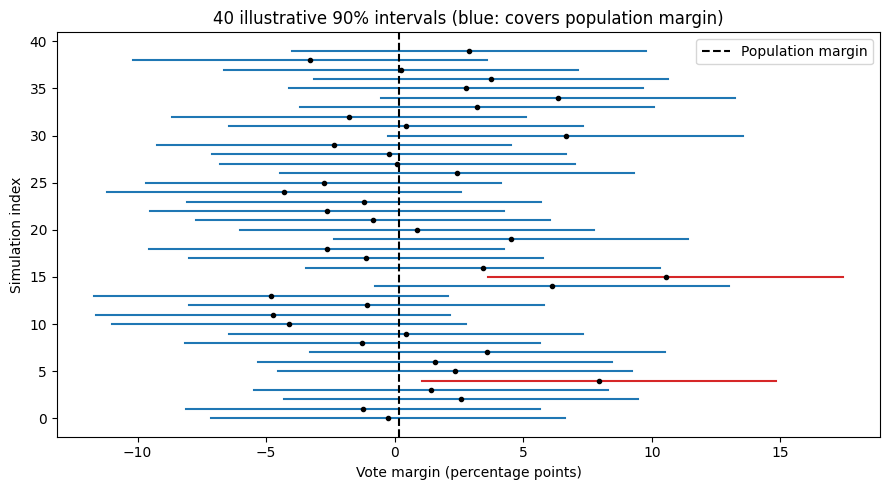

In [5]:
z90 = 1.6448536269514722
se_approx = margins_100.std(ddof=1)
low = margins_100 - z90 * se_approx
high = margins_100 + z90 * se_approx
coverage = np.mean((low <= population_margin) & (population_margin <= high))
print(f"Approximate 90% interval coverage: {coverage:.1%}")

fig, ax = plt.subplots(figsize=(9, 5))
selected = np.arange(40)
contains = (low[selected] <= population_margin) & (population_margin <= high[selected])
for i in selected:
    ax.plot([low[i], high[i]], [i, i], color="tab:blue" if contains[i] else "tab:red", linewidth=1.5)
    ax.plot(margins_100[i], i, marker="o", markersize=3, color="black")
ax.axvline(population_margin, color="black", linestyle="--", label="Population margin")
ax.set(xlabel="Vote margin (percentage points)", ylabel="Simulation index",
       title="40 illustrative 90% intervals (blue: covers population margin)")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Interpretation and limitations

- The 100-table samples should show a **narrower sampling distribution** than the 5-table samples, illustrating the value of larger samples.
- A close population margin means that even moderately sized random samples may identify the wrong winner.
- The Monte Carlo **correct-winner percentage** describes this artificial sampling experiment, not the reliability of any real-world polling organisation.
- Voting tables are treated as equally likely sampling units; real polls have nonresponse, stratification, weighting, cluster effects and other design features.
- Missing-data exclusions alter the analysis population slightly. The exercise does not assess electoral fraud or adjudicate political claims.
- The dataset is a historical educational extract. The original source and redistribution permissions should be verified before posting the raw CSV publicly.

**Portfolio skills:** data validation, NumPy random sampling, simulation design, distribution visualisation, uncertainty quantification and confidence-interval coverage.